# Along-isobath averaging

This recipe averages ocean properties **within depth bins** on the Antarctic continental shelf and slope in ACCESS-OM2-01. In some areas of the slope, these depth bins align and follow isobaths at the slope, and so this averaging is essentially an along isobath average. This is not guaranteed to happen everywhere! Read Caveat 1. below. 

The method works for scalar fields and for vector components that have **not** been rotated into along/across-isobath directions (e.g. the $x$-velocity `u`, which stays the model grid's $x$-component). This example only uses temperature; to average `u` with the same weights, first interpolate it onto the tracer grid.

For every grid cell in the region we know its bottom depth $h$ (`ht`). We group the cells into isobath bins $[h_b, h_{b+1})$ and, at each depth level $z$ and time $t$, compute a volume-weighted mean:

$$
\overline{T}(t, z, h_b) = \frac{\sum_{h_b \le h < h_{b+1}} T\,V}{\sum_{h_b \le h < h_{b+1}} V}, \qquad V = \texttt{area\_t} \times \texttt{dzt}
$$

The sums are computed with [`xhistogram`](https://xhistogram.readthedocs.io), using `ht` as the binned quantity and $V$ (or $T V$) as the weights.

The steps are:

1. Load the bathymetry `ht` and build a mask for the region of interest (the Ross Sea, shallower than 2000 m).
2. Load temperature and cell thickness `dzt`, and build the cell volume from `area_t` and `dzt`.
3. Bin the volume-weighted fields by isobath and divide by the binned volume.
4. Plot the results against isobath depth, then against the cumulative fraction of shelf area (a "pseudo-latitude").

#### Caveats

1. **The mask matters.** A deep trough on the shelf gets averaged with the slope offshore at the same depth. A seamount offshore gets averaged with the shallow shelf. Check that your region contains only the topography you mean to compare.
2. **Bins near the sea floor are partial.** Bottom depths `ht` include partial bottom cells, so they do not line up with the vertical levels `st_ocean`. A bin can therefore mix columns whose deepest wet cell is in different levels. As a result, the lowest one or two levels of each isobath column hold fewer cells than the levels above them.

#### Converting to MOM6

The method doesn't depend on the model, but the names do. For a MOM6 run (e.g. ACCESS-OM3) the closest equivalents are:

| ACCESS-OM2 (MOM5) | MOM6 |
|---|---|
| `temp` (K) | `thetao` (°C) |
| `dzt` | `thkcello` |
| `area_t` | `areacello` |
| `ht` | `deptho` |
| `st_ocean`, `st_edges_ocean` | `z_l`, `z_i` (or the model's native vertical coordinate) |
| `xt_ocean`, `yt_ocean` | `xh`, `yh` |

Note that MOM6 `thetao` is already in °C, so skip the K → °C conversion (`- 273.15`) when loading.

In [1]:
import intake
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from xhistogram.xarray import histogram
from dask.distributed import Client

In [2]:
client = Client(threads_per_worker=1)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 28
Total threads: 28,Total memory: 251.19 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:43347,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:34437,Total threads: 1
Dashboard: http://127.0.0.1:39983/status,Memory: 8.97 GiB
Nanny: tcp://127.0.0.1:34331,


## 1. Load the bathymetry and choose the region
We use the 0.1° repeat-year-forcing experiment `01deg_jra55v13_ryf9091`, forced every year with the same JRA55-do atmosphere (May 1990 to April 1991). First we load the bathymetry and decide the region of interest.

In [3]:
catalog = intake.cat.access_nri
experiment = '01deg_jra55v13_ryf9091' # the RYF90-91 experiment

esm_ds = catalog[experiment]
bathy = esm_ds.search(variable=['ht'], frequency='fx').to_dask()
ht = bathy['ht']

For this example, we will select a small region of the shelf and slope in the Ross Sea sector. We will also create a mask that keeps only depths shallower than 2000 m, so deeper water is excluded from the "along-isobath" average.

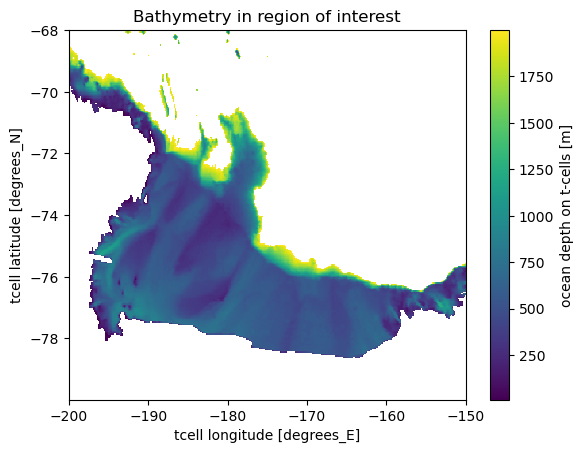

In [4]:
# Define the region of interest
lon_slice = slice(-200, -150)
lat_slice = slice(-80, -68)
mask_depth = 2000

# select the region of interest in ht:
ht = ht.sel(xt_ocean=lon_slice).sel(yt_ocean=lat_slice)

# create masks:
mask_t = ht < mask_depth
mask_t = mask_t.where(mask_t != 0)

# mask bathymetry:
ht_masked = ht * mask_t

# Plot the bathymetry in the mask region:
ht_masked.plot()
plt.title('Bathymetry in region of interest')
plt.show()

## 2. Load temperature and cell thickness

Now we can load the rest of the diagnostics needed in this example. We will need temperature (`temp`) which is on tracer cells. To weight the averages we need each cell's volume, $V = \texttt{area\_t} \times \texttt{dzt}$, where `dzt` is the thickness of the cells. Because `dzt` changes with time (sea level moves), $V$ is a function of time too. Note that if you want to choose diagnostics in other grids, you will have to adapt the calculation of volume. 

We will use a preprocessing function to only extract the region of interest, and open a single year (2170).

In [5]:
def preprocess(ds):
    ds = ds.sel(xt_ocean=lon_slice, yt_ocean=lat_slice)
    return ds

var_dataset = esm_ds.search(variable=['temp','dzt'],
                            frequency='1mon', 
                            start_date='2170.*').to_dask(preprocess=preprocess)
temp = var_dataset['temp']-273.15
dzt = var_dataset['dzt']
area_t = esm_ds.search(variable=['area_t'], frequency='fx').to_dask(preprocess=preprocess)['area_t']

We also need the depth levels `st_ocean` and their edges `st_edges_ocean`, which are stored in the monthly grid file. The catalog has more than one monthly file with these coordinates, so we first list their `file_id`s and then select the one that matches the 3600 × 2700 grid.

In [6]:
coord_ds = esm_ds.search(
    variable=['xt_ocean','yt_ocean','st_edges_ocean','st_ocean'], 
    file_id='ocean.1mon.grid_xt_ocean:3600.grid_xu_ocean:3600.grid_yt_ocean:2700.grid_yu_ocean:2700.neutral:80.neutralrho_edges:81.nv:2.potrho:80.potrho_edges:81.st_edges_ocean:76.st_ocean:75.sw_edges_ocean:76.sw_ocean:75.xt_ocean:3600.xu_ocean:3600.yt_ocean:2700.yu_ocean:2700',
    frequency='1mon'
).to_dask()
xt_ocean = coord_ds['xt_ocean'].sel(xt_ocean=lon_slice)
yt_ocean = coord_ds['yt_ocean'].sel(yt_ocean=lat_slice)
st_ocean = coord_ds['st_ocean']
st_edges_ocean = coord_ds['st_edges_ocean']

In [7]:
volume = area_t * dzt

Now let's apply the region mask to the volume, area and temperature. Below the sea floor `temp` is NaN, so we also drop the volume of those cells. That way the numerator ($\sum T V$) and denominator ($\sum V$) of each mean cover exactly the same cells.

In [8]:
volume_masked = volume * mask_t
area_t_masked = area_t * mask_t
temp_masked = temp * mask_t

# Only keep the volume of wet cells (where there is a temperature)
volume_masked = volume_masked.where(temp_masked.notnull())

## 3. Bin the variables by depth

For the isobath bin edges we use `st_edges_ocean`, the edges of the model's vertical levels. This makes the isobath resolution match the vertical resolution - there's not much point in trying to bin into finer bins.

`xhistogram.histogram` sums its `weights` over all cells (`yt_ocean`, `xt_ocean`) applying the bins to `ht_masked`. It keeps the other dimensions (`time`, `st_ocean`), so each result has dimensions `(time, st_ocean, ht_bin)`. We compute:

- `V_sum`: the volume in each bin and level,
- `A_sum`: the horizontal area in each bin (used for the area axis in step 4),
- `TV_sum`: the volume-weighted sums of temperature.

Cells outside the region or below the sea floor are NaN; we give them zero weight (`.fillna(0)`) so they add nothing to the sums. The isobath means are then `T_mean = TV_sum / V_sum`, left as NaN where a bin has no water. All of these are lazy dask arrays: nothing is computed until we plot.

In [9]:
depth_bins = st_edges_ocean.values

V_sum = histogram(ht_masked, bins = depth_bins,
                  dim = ['yt_ocean', 'xt_ocean'],
                  weights = volume_masked.fillna(0))
A_sum = histogram(ht_masked, bins = depth_bins,
                  dim = ['yt_ocean', 'xt_ocean'],
                  weights = area_t_masked.fillna(0))
TV_sum = histogram(ht_masked, bins = depth_bins,
                   dim = ['yt_ocean', 'xt_ocean'],
                   weights = (volume_masked * temp_masked).fillna(0))

T_mean = TV_sum / V_sum.where(V_sum>0)

## 4. Plot the isobath-averaged fields

First we plot the time-mean temperature against isobath depth. The data stop along a diagonal: an isobath bin $h$ has no water below depth $h$, so the sea floor appears as the line *depth = isobath*.

The time mean here is a plain mean over the monthly records, not weighted by the number of days in each month.

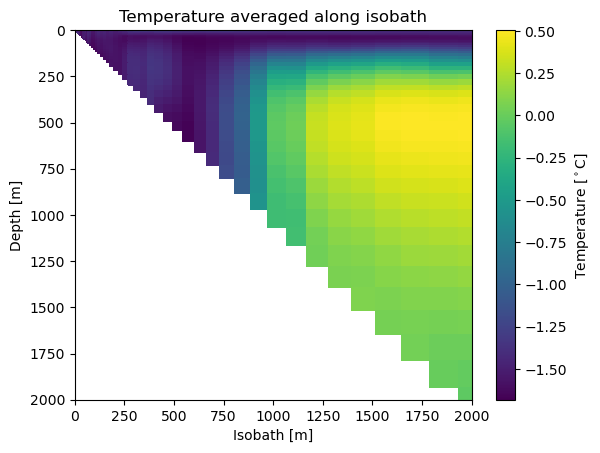

In [10]:
plt.pcolor(T_mean.ht_bin, temp_masked.st_ocean, T_mean.mean('time'))
plt.gca().invert_yaxis()
plt.ylim(2000,0)
plt.xlim(0,2000)
plt.xlabel('Isobath [m]')
plt.ylabel('Depth [m]')
plt.colorbar(label = r'Temperature [$^\circ$C]')
plt.title('Temperature averaged along isobath');

### Rescale the x-axis by area

The isobath axis gives as much width to a 2000 m bin with little area as to a shelf bin covering a large area. Instead, we can place each bin at the **cumulative fraction of horizontal area** shallower than its middle (`normalised_area_cumsum`: all shallower bins plus half of the bin itself, running from 0 at the coast to 1 at the 2000 m limit). On this axis, distance is proportional to the area of shelf and slope covered.

We also map this fraction linearly onto the region's latitude range (80°S at 0, 68°S at 1) to give a "pseudo-latitude" axis. This is only a relabelling of the 0–1 axis, not the actual latitude of the isobaths.

In [11]:
# Cumulative fraction of the horizontal area, at the middle of each isobath bin:
# all shallower bins plus half of this bin
normalised_area_cumsum = ((A_sum.cumsum('ht_bin') - 0.5 * A_sum) / A_sum.sum('ht_bin')).values

# Southern and northern edges of the region, in degrees south (80 and 68 here)
lat_south, lat_north = abs(mask_t.yt_ocean.min().values), abs(mask_t.yt_ocean.max().values)

## Here, we plot the averaged quantities as a function of normalised area (between 0 and 1)
## and pseudo-latitude
def normalised_to_pseudo_lat(normalised_area):
    return -1 * (lat_south - (lat_south - lat_north) * normalised_area)

def pseudo_lat_to_normalised(pseudo_lat):
    return (lat_south + pseudo_lat) / (lat_south - lat_north)

pseudo_lat = normalised_to_pseudo_lat(normalised_area_cumsum)

Finally, we plot time-mean temperature against the normalised area, with the pseudo-latitude on a secondary axis at the top. Temperatures outside ±2 °C are shown in the end colours (the arrows on the colour bar).

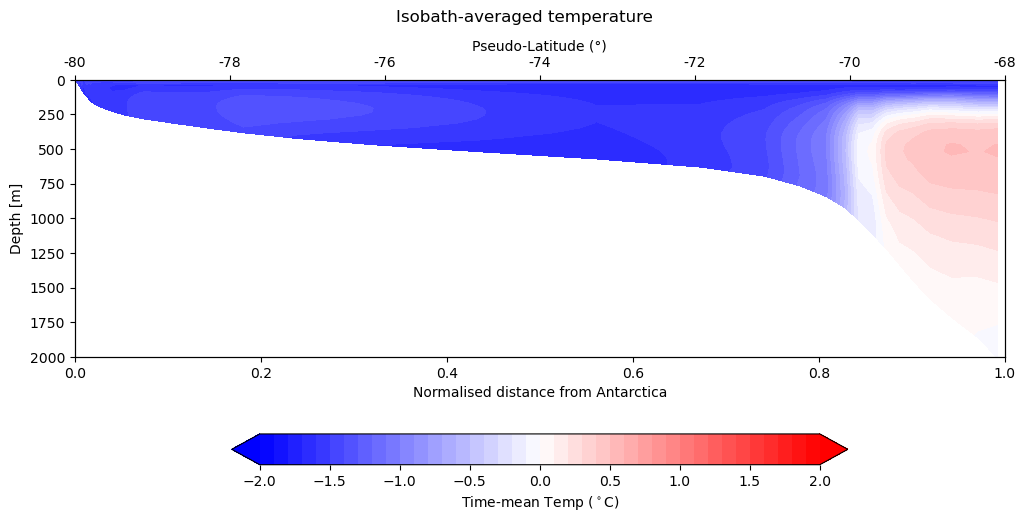

In [12]:
fig, axs = plt.subplots(1, 1, figsize=(12, 5), facecolor='w', edgecolor='k')

im1 = axs.contourf(normalised_area_cumsum, st_ocean, T_mean.mean('time'),
                   levels=np.linspace(-2, 2, 41), extend='both', cmap=plt.cm.bwr)

axs.invert_yaxis()
axs.set_xlabel('Normalised distance from Antarctica')
axs.set_ylim(mask_depth, 0)

# Secondary x-axis: pseudo_lat
twin_ax = axs.twiny()
twin_ax.set_xlim(axs.get_xlim())  # Align the limits to match the shared x-axis
twin_ax.set_xticks(pseudo_lat_to_normalised(np.arange(-80, -67, 2)))  # Match tick positions
twin_ax.set_xticklabels(np.arange(-80, -67, 2))  # Replace tick labels with pseudo_lat values
twin_ax.set_xlabel('Pseudo-Latitude (°)')

axs.set_ylabel('Depth [m]')

cb1 = plt.colorbar(im1, fraction=0.08, pad=0.2, orientation='horizontal')

cb1.set_label(r'Time-mean Temp ($^\circ$C)')

fig.suptitle('Isobath-averaged temperature', y=1.02);

In [13]:
client.close()